In [1]:

# Bias-Variance Tradeoff & Regularisation
# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Create a sample dataset with a nonlinear pattern

np.random.seed(42)

X = np.linspace(-3, 3, 100).reshape(-1, 1)
y = 0.5 * X.ravel()**3 - X.ravel()**2 + 2 * X.ravel()
y = y + np.random.normal(0, 3, 100)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Dataset created successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Dataset created successfully!
Training samples: 80
Testing samples: 20


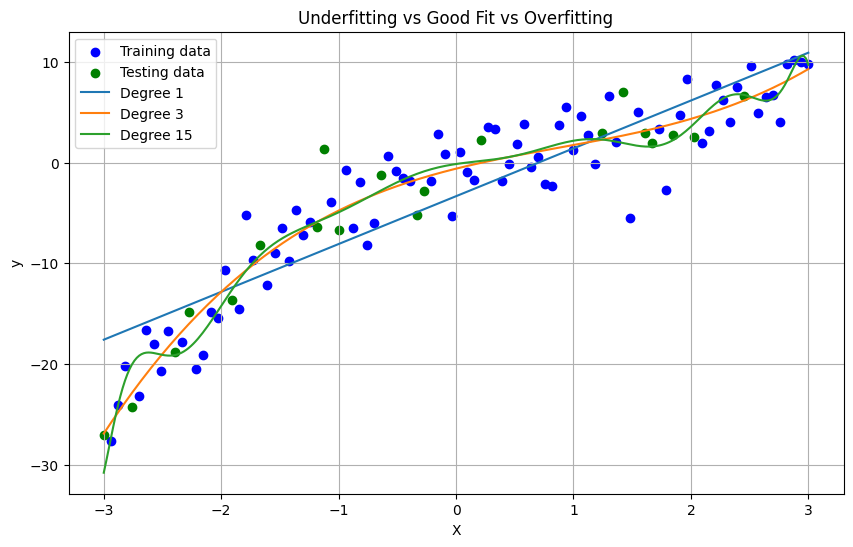

In [5]:

# Compare models with different complexity

degrees = [1, 3, 15]
models = {}

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color="blue", label="Training data")
plt.scatter(X_test, y_test, color="green", label="Testing data")

X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)
    models[degree] = model

    y_plot = model.predict(X_plot)
    plt.plot(X_plot, y_plot, label=f"Degree {degree}")

plt.title("Underfitting vs Good Fit vs Overfitting")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()


In [7]:

# Evaluate each model on training and testing data

results = []

for degree, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": f"Polynomial Degree {degree}",
        "Train MSE": mean_squared_error(y_train, train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred)
    })

results_df = pd.DataFrame(results)
print(results_df.round(3).to_string(index=False))


               Model  Train MSE  Test MSE  Train R2  Test R2
 Polynomial Degree 1     15.010    19.169     0.821    0.800
 Polynomial Degree 3      7.344     5.420     0.913    0.943
Polynomial Degree 15      6.438     7.780     0.923    0.919


In [9]:

# Step 6: Compare Linear Regression, Ridge, and Lasso

# Use degree 15 to demonstrate how regularisation controls complexity
ridge_model = make_pipeline(
    PolynomialFeatures(degree=15),
    StandardScaler(),
    Ridge(alpha=10)
)

lasso_model = make_pipeline(
    PolynomialFeatures(degree=15),
    StandardScaler(),
    Lasso(alpha=0.1, max_iter=100000)
)

# Train the models
ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

# Evaluate model performance
regularised_models = {
    "Ridge": ridge_model,
    "Lasso": lasso_model
}

for name, model in regularised_models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    print(f"\n{name} Regression")
    print("Training MSE:", round(mean_squared_error(y_train, train_pred), 3))
    print("Testing MSE:", round(mean_squared_error(y_test, test_pred), 3))
    print("Testing R2:", round(r2_score(y_test, test_pred), 3))



Ridge Regression
Training MSE: 8.067
Testing MSE: 5.926
Testing R2: 0.938

Lasso Regression
Training MSE: 7.351
Testing MSE: 5.557
Testing R2: 0.942


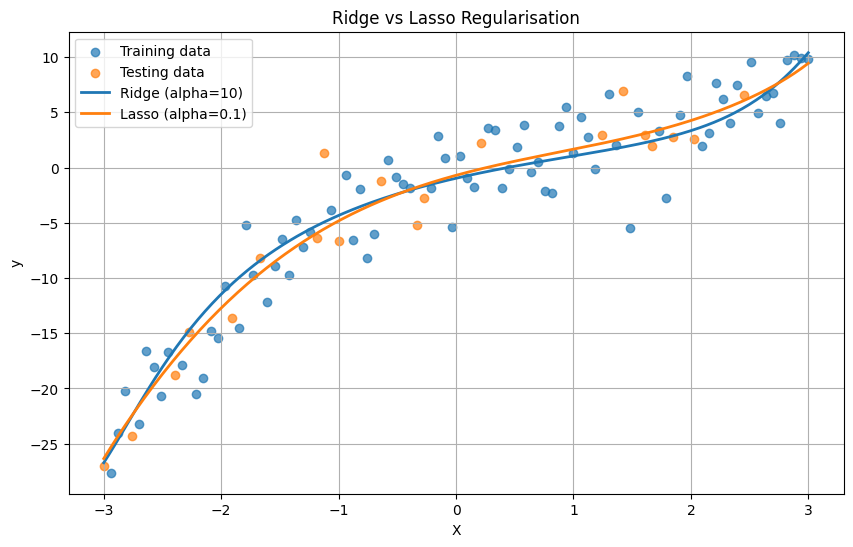

In [10]:

# Plot Ridge and Lasso predictions against the observed data

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, label="Training data", alpha=0.7)
plt.scatter(X_test, y_test, label="Testing data", alpha=0.7)

X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)

plt.plot(
    X_plot, ridge_model.predict(X_plot),
    label="Ridge (alpha=10)", linewidth=2
)
plt.plot(
    X_plot, lasso_model.predict(X_plot),
    label="Lasso (alpha=0.1)", linewidth=2
)

plt.title("Ridge vs Lasso Regularisation")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()


In [11]:

# Final comparison of all models

all_models = {
    "Polynomial Degree 1": models[1],
    "Polynomial Degree 3": models[3],
    "Polynomial Degree 15": models[15],
    "Ridge Regularisation": ridge_model,
    "Lasso Regularisation": lasso_model
}

comparison = []

for name, model in all_models.items():
    comparison.append({
        "Model": name,
        "Train MSE": mean_squared_error(
            y_train, model.predict(X_train)
        ),
        "Test MSE": mean_squared_error(
            y_test, model.predict(X_test)
        ),
        "Test R2": r2_score(
            y_test, model.predict(X_test)
        )
    })

comparison_df = pd.DataFrame(comparison).round(3)
print(comparison_df.to_string(index=False))

# Save results as a CSV file
comparison_df.to_csv("bias_variance_results.csv", index=False)
print("\nResults saved to bias_variance_results.csv")


               Model  Train MSE  Test MSE  Test R2
 Polynomial Degree 1     15.010    19.169    0.800
 Polynomial Degree 3      7.344     5.420    0.943
Polynomial Degree 15      6.438     7.780    0.919
Ridge Regularisation      8.067     5.926    0.938
Lasso Regularisation      7.351     5.557    0.942

Results saved to bias_variance_results.csv


In [12]:

# Step 8: Tune Ridge and Lasso using cross-validation

from sklearn.model_selection import GridSearchCV

# Ridge: search for the best regularisation strength
ridge_pipeline = make_pipeline(
    PolynomialFeatures(degree=15),
    StandardScaler(),
    Ridge()
)

ridge_grid = GridSearchCV(
    ridge_pipeline,
    {"ridge__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    scoring="neg_mean_squared_error"
)

ridge_grid.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_)
print("Best Ridge CV MSE:", round(-ridge_grid.best_score_, 3))
print("Ridge Test MSE:", round(
    mean_squared_error(y_test, ridge_grid.predict(X_test)), 3
))

# Lasso: search for the best regularisation strength
lasso_pipeline = make_pipeline(
    PolynomialFeatures(degree=15),
    StandardScaler(),
    Lasso(max_iter=100000)
)

lasso_grid = GridSearchCV(
    lasso_pipeline,
    {"lasso__alpha": [0.001, 0.01, 0.1, 1, 10]},
    cv=5,
    scoring="neg_mean_squared_error"
)

lasso_grid.fit(X_train, y_train)

print("\nBest Lasso alpha:", lasso_grid.best_params_)
print("Best Lasso CV MSE:", round(-lasso_grid.best_score_, 3))
print("Lasso Test MSE:", round(
    mean_squared_error(y_test, lasso_grid.predict(X_test)), 3
))


Best Ridge alpha: {'ridge__alpha': 0.01}
Best Ridge CV MSE: 8.931
Ridge Test MSE: 7.927

Best Lasso alpha: {'lasso__alpha': 0.1}
Best Lasso CV MSE: 8.432
Lasso Test MSE: 5.557


In [13]:

# Compare the tuned Ridge and Lasso models

tuned_models = {
    "Tuned Ridge": ridge_grid.best_estimator_,
    "Tuned Lasso": lasso_grid.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():
    tuned_results.append({
        "Model": name,
        "Best Alpha": model.named_steps[
            "ridge" if "Ridge" in name else "lasso"
        ].alpha,
        "Train MSE": mean_squared_error(
            y_train, model.predict(X_train)
        ),
        "Test MSE": mean_squared_error(
            y_test, model.predict(X_test)
        ),
        "Test R2": r2_score(
            y_test, model.predict(X_test)
        )
    })

tuned_df = pd.DataFrame(tuned_results).round(3)
print(tuned_df.to_string(index=False))

# Save tuned results
tuned_df.to_csv("tuned_regularisation_results.csv", index=False)
print("\nTuned results saved successfully!")


      Model  Best Alpha  Train MSE  Test MSE  Test R2
Tuned Ridge        0.01      6.740     7.927    0.917
Tuned Lasso        0.10      7.351     5.557    0.942

Tuned results saved successfully!
